# Веломаршрут по популярным улицам

Постройте маршруты A–B по улицам, где действительно ездят велосипедисты, не сильно длиннее кратчайшего пути.
Популярность улиц — поездки STADTRADELN 2024 в Констанце. Итог считается на закрытой части города.
Меняйте ячейки с ✏️.

In [1]:
from pathlib import Path
import sys

import networkx as nx
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
from cycle_routing.graph import drop_values
from cycle_routing.workshop import (
    build_network, comfort_cost, data_dictionary, example_rows, export_solution, feature_catalog, gpx_table,
    load_city, ml_feature, presets, preview_cost, preview_features, rideable, score, solution, train_model,
    train_popularity,
)
from cycle_routing.workshop_maps import plot_network, plot_pairs, plot_popularity, route_explorer

PACK = "konstanz_more"  # набор данных: другое разбиение города — другое имя
city = load_city(ROOT / "notebooks/data/hackathon" / PACK)
OUTPUT = ROOT / "outputs/hackathon" / PACK

## 1. Данные

`city.roads` — участки дорог, `city.trips` — поездки по участку (известны только в открытой части города),
`city.pairs` — тестовые пары. Ниже — все значения каждого столбца и несколько строк, где заполнен каждый столбец.

In [2]:
display(data_dictionary(city))
display(example_rows(city))

,тип,значения
длина_м,"число, м",0.287916 … 2980.02
тип_дороги,категория,"footway, service, residential, path, track, steps, secondary, living_street, tertiary, cycleway, primary, unclassified, pedestrian, trunk_link, corridor, primary_link, bus_stop, trunk, motorway, secondary_link, tertiary_link, motorway_link, bridleway"
покрытие,категория,"asphalt, paving_stones, fine_gravel, gravel, compacted, unpaved, pebblestone, grass, sett, dirt, concrete, paved, ground, woodchips, wood, grass_paver, earth, concrete:plates, metal, unhewn_cobblestone, stone, mud, rock, rubber, cobblestone, sand, metal_grid, tartan, 3, concrete:lanes; пусто — нет данных"
ровность,категория,"good, excellent, intermediate, bad, very_bad, very_horrible, wheels, horrible, robust_wheels, thin_rollers, high_clearance, off_road_wheels, impassable, thin_wheels, specialized_off_road_wheels; пусто — нет данных"
велополоса,категория,"no, separate, lane, track, share_busway, crossing, shared_lane, designated, yes; пусто — нет данных"
велосипед,категория,"designated, yes, no, use_sidepath, dismount, agricultural, forestry, permissive, discouraged, destination, unknown; пусто — нет данных"
освещение,категория,"yes, no, automatic, 24/7, limited; пусто — нет данных"
служебный_проезд,категория,"driveway, parking_aisle, alley, drive-through, emergency_access, slipway, yes, tiefgarageneinfahrt; пусто — нет данных"
доступ,категория,"private, no, yes, permissive, customers, destination, delivery, agricultural, permit, designated, forestry; пусто — нет данных"
макс_скорость,"число, км/ч",5 … 100; пусто — нет данных


,длина_м,тип_дороги,покрытие,ровность,велополоса,велосипед,освещение,служебный_проезд,доступ,макс_скорость,полос,ширина_м,одностороннее
641,17.386630,tertiary,asphalt,excellent,no,yes,no,NaN,yes,60.0,2.0,7.5,False
12112,35.823359,residential;service,asphalt,excellent,no,NaN,yes,driveway,private,30.0,NaN,NaN,False


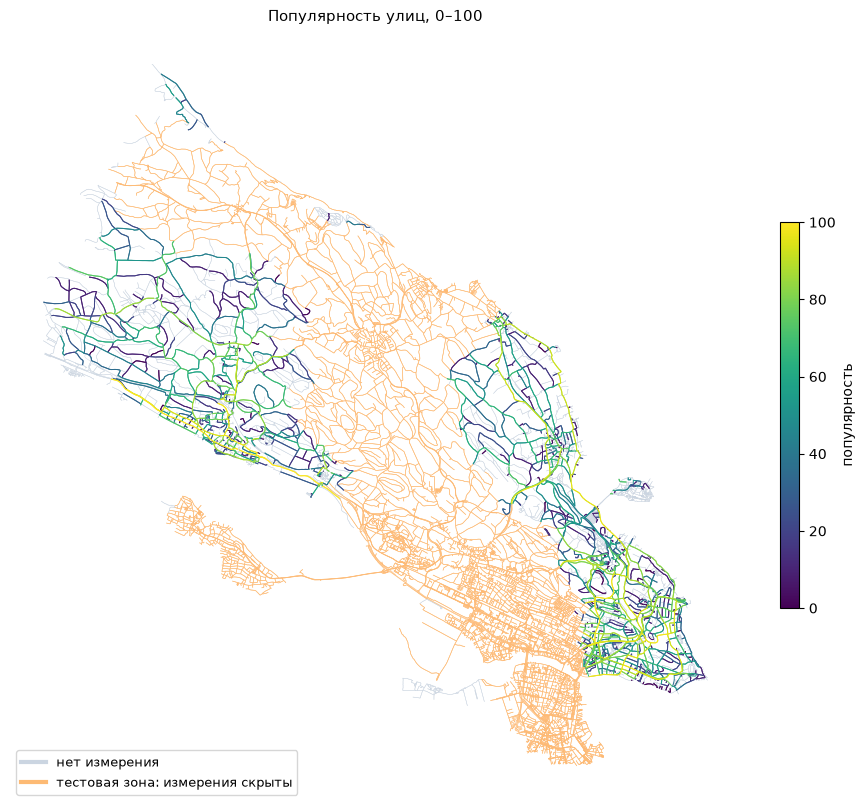

In [3]:
plot_popularity(city);

## 2. Фильтр ✏️

Какие дороги можно использовать. Участки, оторванные от основной сети, в маршрутах не используются.

Осталось 38,333 участков (2528 км) из 44,460. Фильтр убрал 4,155 (261 км), оторвано от основной сети и не используется 1,972 (60 км).


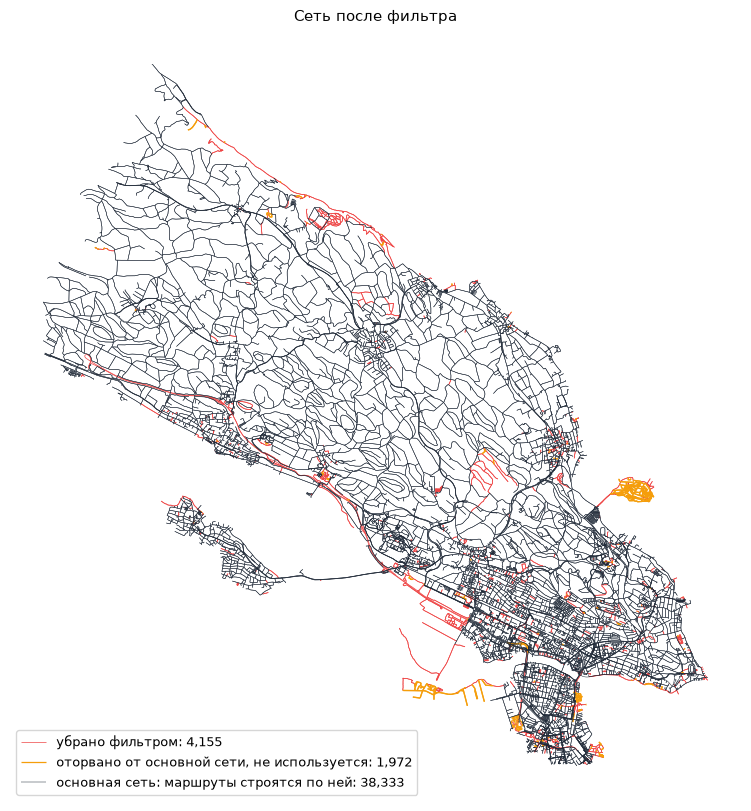

In [4]:
def keep(roads):
    ok = rideable(roads)  # готовый фильтр: без лестниц, запретов для велосипеда и частных проездов
    # ok &= drop_values(roads, тип_дороги=["primary"])  # пример: ещё убрать крупные дороги
    return ok

network = build_network(city, keep)
print(network.summary())
plot_network(network);

## 3. Тестовые пары

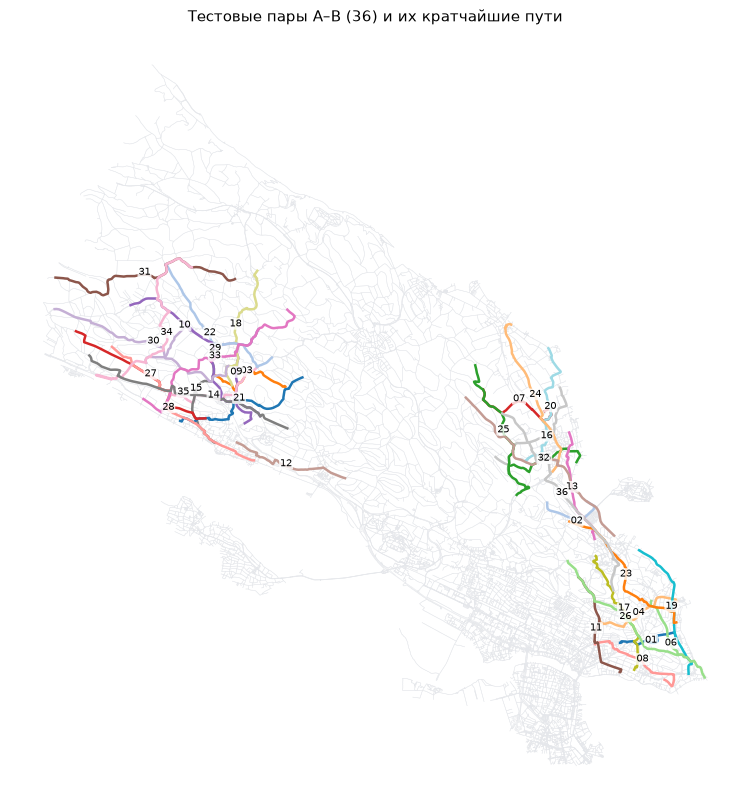

In [5]:
plot_pairs(city);

## 4. Решение ✏️

Стоимость участка = длина × (1 + Σ вес × признак). Плюс — избегать, минус — предпочитать.
Готовые признаки ниже уже посчитаны из тегов для каждого участка. Свои добавляйте в `my_features`:
их можно взвешивать так же, как готовые.

In [6]:
feature_catalog()

,значения,из чего
велодорожка,0/1,тип_дороги = cycleway или велополоса на дороге
крупная_дорога,0/1,"тип_дороги = primary, secondary, trunk"
жилая_улица,0/1,"тип_дороги = residential, living_street"
пешеходная,0/1,"тип_дороги = footway, pedestrian, steps, path"
плохое_покрытие,0/1,"брусчатка, грунт, гравий или плохая ровность"
без_освещения,0/1,освещение = no
узкая,0/1,ширина_м < 2
скорость,км/ч,макс_скорость; нет данных → 30
полосы,число,полос; нет данных → 1
ширина,м,ширина_м; нет данных → 3


### Свои признаки ✏️

Пример: два новых признака. Таблица под кодом показывает участки, где они есть.

In [7]:
def my_features(roads):
    f = pd.DataFrame(index=roads.index)
    f["быстрые_машины"] = roads["макс_скорость"].ge(50).astype(float)  # 1, если машины едут 50 км/ч и быстрее
    f["асфальт"] = roads["покрытие"].eq("asphalt").astype(float)
    return f

preview_features(city, my_features)

,тип_дороги,быстрые_машины,асфальт
641,tertiary,1.0,1.0
9812,tertiary,1.0,1.0
3352,service,0.0,1.0
694,footway,0.0,1.0
263,residential,0.0,1.0


### Веса ✏️

Свои признаки стоят в весах рядом с готовыми. Быстрая проверка без поиска маршрутов: признаки с весом
на примерах дорог и стоимость участка в последнем столбце.

In [8]:
WEIGHTS = {"крупная_дорога": 0.6, "плохое_покрытие": 0.4, "велодорожка": -0.4, "без_освещения": 0.2,
           "быстрые_машины": 0.3, "асфальт": -0.2}
my_cost = comfort_cost(WEIGHTS, extra=my_features)
preview_cost(city, my_cost)

,тип_дороги,крупная_дорога,плохое_покрытие,велодорожка,без_освещения,быстрые_машины,асфальт,длина_м,цена 1 м,стоимость
724,secondary,1.0,0.0,0.0,1.0,1.0,1.0,24.3,1.9,46.1
18975,footway;residential,0.0,1.0,0.0,0.0,0.0,0.0,141.4,1.4,198.0
260,secondary,1.0,0.0,1.0,0.0,0.0,1.0,23.4,1.0,23.4
641,tertiary,0.0,0.0,0.0,1.0,1.0,1.0,17.4,1.3,22.6
9812,tertiary,0.0,0.0,0.0,1.0,1.0,1.0,379.9,1.3,493.8
9813,tertiary,0.0,0.0,0.0,1.0,1.0,1.0,427.2,1.3,555.4


### Своя формула ✏️

Необязательно: формула целиком — функция `roads → положительная стоимость каждого участка`.
Здесь она использует те же свои признаки; в сравнении ниже это решение «моя формула».

In [9]:
def my_formula(roads):
    f = my_features(roads)
    return roads["длина_м"] * (1 + 0.8 * f["быстрые_машины"] - 0.3 * f["асфальт"])

preview_cost(city, my_formula, extra=my_features)

,тип_дороги,быстрые_машины,асфальт,длина_м,цена 1 м,стоимость
641,tertiary,1.0,1.0,17.4,1.5,26.1
9812,tertiary,1.0,1.0,379.9,1.5,569.8
3352,service,0.0,1.0,104.1,0.7,72.9
694,footway,0.0,1.0,79.3,0.7,55.5
263,residential,0.0,1.0,42.3,0.7,29.6


### Повороты и поиск ✏️

In [10]:
TURNS = {"left_penalty_m": 30, "right_penalty_m": 10}  # None — без штрафов; "min_turns" — готовый режим

def my_search(graph, source, target, weight):
    # двусторонний Дейкстра: тот же путь, что у обычного, но быстрее
    return nx.bidirectional_dijkstra(graph, source, target, weight=weight)[1]

mine = solution(my_cost, turns=TURNS, search=my_search, label="моё решение")
formula = solution(my_formula, turns=TURNS, search=my_search, label="моя формула")

## 5. ML ✏️

Необязательно: модель предсказывает популярность улицы, а прогноз становится признаком `ml_популярность` (0–1).
Готовая модель — градиентный бустинг по тегам OSM.

In [11]:
model = train_popularity(city)
ml_cost = comfort_cost({**WEIGHTS, "ml_популярность": -0.8}, extra=[my_features, ml_feature(model)])
with_ml = solution(ml_cost, turns=TURNS, search=my_search, label="моё + ML")

Связь прогноза с реальной популярностью на отложенных улицах: 0.64 (1 — идеально, 0 — никакой)


### Своя модель ✏️

Любая модель sklearn с `fit` и `predict`. Она учится на готовых признаках и ваших `my_features`
предсказывать `log(1 + поездки)`. Пример специально слабый — дерево глубины 1; попробуйте лучше.

In [12]:
from sklearn.tree import DecisionTreeRegressor

my_model = train_model(city, DecisionTreeRegressor(max_depth=1), extra=my_features)
my_ml_cost = comfort_cost({**WEIGHTS, "ml_популярность": -0.8}, extra=[my_features, ml_feature(my_model)])
with_my_ml = solution(my_ml_cost, turns=TURNS, search=my_search, label="моё + своя ML")

Признаки модели: велодорожка, крупная_дорога, жилая_улица, пешеходная, плохое_покрытие, без_освещения, узкая, скорость_неизвестна, скорость, полосы_неизвестны, полосы, ширина_неизвестна, ширина, покрытие_неизвестно, быстрые_машины, асфальт
Связь прогноза с реальной популярностью на отложенных улицах: 0.26 (1 — идеально, 0 — никакой)


## 6. Сравнение

**популярность** — главный критерий, 0–100. Улица без измерения считается средней (50).
Если маршрут длиннее кратчайшего больше чем на 20%, в оценку этой пары идёт популярность кратчайшего:
большой объезд не даёт выигрыша.

Routes by preset:   0%|          | 0/8 [00:00<?, ?it/s]

Routes by preset: 100%|██████████| 8/8 [00:01<00:00,  6.41it/s]


,популярность,популярнее кратчайшего,"объезд, %",поворотов,"неудобные участки, м","время поиска, мс"
fast,72.1,31 из 36,6.7,6.9,0.0,13.69
balanced,71.5,31 из 36,6.4,7.5,0.0,13.53
моё + ML,69.3,21 из 36,13.7,7.2,0.0,8.56
min_turns,68.9,25 из 36,6.5,3.8,0.0,12.77
моё,68.0,28 из 36,4.2,6.8,0.0,9.84
моё + своя ML,66.4,18 из 36,12.8,7.1,0.0,7.76
моя формула,65.8,22 из 36,4.5,6.2,0.0,11.20
кратчайший,60.7,—,0.0,7.4,0.0,5.22


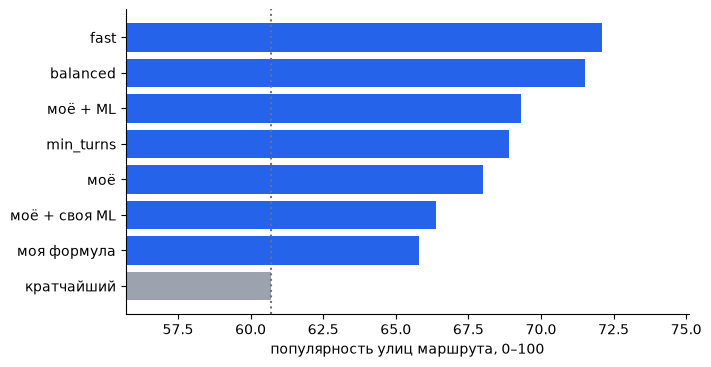

In [13]:
solutions = {"моё": mine, "моя формула": formula, "моё + ML": with_ml, "моё + своя ML": with_my_ml,
             **presets("balanced", "fast", "min_turns")}
result = score(city, solutions, network=network)
display(result.table)
result.plot();

## 7. Разбор маршрутов

Выберите пару и решение; щелчок по участку покажет его теги.

In [14]:
route_explorer(city, result, filename=OUTPUT / "routes.html")

## 8. Петербург

Решение переносится без изменений; красные линии — реальные поездки (GPX). Совпадение — доля длины маршрута
в пределах 30 м от ближайшей поездки. Блок работает, если есть набор Петербурга.

In [15]:
SPB = ROOT / "notebooks/data/hackathon/saint_petersburg"
if (SPB / "manifest.json").exists():
    spb = load_city(SPB)
    spb_result = score(spb, {"моё": mine, "моё + ML": with_ml}, network=build_network(spb, keep))
    display(gpx_table(spb_result, spb.tracks))
    display(route_explorer(spb, spb_result, tracks=spb.tracks, filename=OUTPUT / "spb_routes.html"))
else:
    print("Набора Петербурга нет — блок пропущен.")

Routes by preset: 100%|██████████| 3/3 [00:01<00:00,  2.16it/s]


,"по ближайшему GPX-треку, %","по любым GPX-трекам, %"
algorithm,,
кратчайший,59.0,75.0
моё,43.0,75.0
моё + ML,21.0,58.0


## 9. Сдача ✏️

In [16]:
CHOSEN = mine  # или formula, with_ml, with_my_ml
folder = export_solution(city, CHOSEN, keep=keep, folder=OUTPUT / "submission")
print("Сдайте папку", folder, "и этот ноутбук")

Сдайте папку d:\PythonProjects\CicleGpx\outputs\hackathon\konstanz_more\submission и этот ноутбук
